# 06 — Customer Risk Scoring & Revenue-at-Risk
### Project: Subscription Churn Prediction & Risk Scoring

---

### Objective of this Notebook:
In this notebook, we turn model predictions into **actionable business decisions**:
1. **Load Data**: Read `data/processed/customer_features.csv`.
2. **Train Model & Predict**: Calculate churn probability for each customer.
3. **0–100 Risk Score**: Convert probability into an intuitive risk score.
4. **Risk Tiers**: Classify accounts into `Low`, `Medium`, `High`, and `Critical`.
5. **Root Cause**: Identify the main reason why each customer is at risk.
6. **Revenue-at-Risk**: Calculate how much Monthly Recurring Revenue (MRR) is exposed.
7. **Decile Analysis**: Find how much churn we capture by targeting the top 10% or 20% of customers.
8. **Export Deliverables**:
   - `data/processed/customer_risk_scores.csv` (for Power BI dashboard).
   - `outputs/high_risk_retention_list.csv` (for the Customer Success / Retention team).

## Step 1: Import Libraries

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingClassifier
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Load the Processed Customer Features
We load the clean feature table created in `04_feature_engineering.ipynb`.

In [12]:
# Load customer features dataset
df = pd.read_csv('C:/Users/Admin/OneDrive/Data Analyst Project/Subscription Churn Prediction & Risk Scoring/data/processed/customer_features.csv')

print(f"Loaded {len(df):,} customers with {df.shape[1]} columns.")
display(df.head(3))

Loaded 20,000 customers with 29 columns.


,customer_id,tenure_months,age_group,gender,region,acquisition_channel,plan,billing_cycle,monthly_fee,discount_pct,...,total_payments,failed_payments,payment_failure_rate,had_failed_payment,total_tickets,avg_resolution_hours,avg_csat,had_low_csat,tickets_per_tenure_month,churn_flag
0,CUST-10000,26,35-44,Male,North America,Paid Ads,Basic,Monthly,15.0,0,...,27,3,0.111,1,2,8.85,3.50,0,0.074,0
1,CUST-10001,15,18-24,Female,Latin America,Organic Search,Basic,Annual,13.5,10,...,2,1,0.500,1,3,16.80,3.00,1,0.188,0
2,CUST-10002,1,45-54,Male,Asia-Pacific,Organic Search,Basic,Monthly,15.0,0,...,2,0,0.000,0,3,11.23,4.33,0,1.500,0


## Step 3: Train the Model & Generate 0–100 Risk Scores
We train Gradient Boosting on the features and predict each customer's probability of leaving:
$$\text{Risk Score} = P(\text{churn}) \times 100$$

In [13]:
# Prepare X and y
X = pd.get_dummies(df.drop(columns=['customer_id', 'churn_flag']), drop_first=True)
y = df['churn_flag']

# Train Gradient Boosting model
print("Training model...")
model = GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=42)
model.fit(X, y)

# Predict churn probability and calculate 0-100 risk score
df['churn_probability'] = model.predict_proba(X)[:, 1].round(4)
df['risk_score'] = (df['churn_probability'] * 100).round(1)

print("Sample Customer Risk Scores:")
display(df[['customer_id', 'plan', 'billing_cycle', 'monthly_fee', 'churn_probability', 'risk_score']].head(5))

Training model...
Sample Customer Risk Scores:


,customer_id,plan,billing_cycle,monthly_fee,churn_probability,risk_score
0,CUST-10000,Basic,Monthly,15.0,0.3881,38.8
1,CUST-10001,Basic,Annual,13.5,0.2102,21.0
2,CUST-10002,Basic,Monthly,15.0,0.2113,21.1
3,CUST-10003,Basic,Monthly,15.0,0.3971,39.7
4,CUST-10004,Basic,Annual,15.0,0.0901,9.0


## Step 4: Categorize Customers into Risk Tiers
We group customers into 4 operational risk levels:
- **Low (0–30)**: Safe & healthy accounts.
- **Medium (31–60)**: Mild risk, monitor engagement.
- **High (61–80)**: High risk, requires outreach.
- **Critical (81–100)**: Imminent cancellation, immediate intervention!

In [14]:
def get_risk_tier(score):
    if score <= 30:
        return 'Low'
    elif score <= 60:
        return 'Medium'
    elif score <= 80:
        return 'High'
    else:
        return 'Critical'

df['risk_tier'] = df['risk_score'].apply(get_risk_tier)

# Summary table of risk tiers
tier_summary = df.groupby('risk_tier', observed=False).agg(
    Customer_Count=('customer_id', 'count'),
    Avg_Risk_Score=('risk_score', 'mean'),
    Actual_Churn_Rate=('churn_flag', 'mean')
).loc[['Low', 'Medium', 'High', 'Critical']].reset_index()

tier_summary['Pct_of_Base'] = (tier_summary['Customer_Count'] / len(df) * 100).round(1)
tier_summary['Actual_Churn_Rate'] = (tier_summary['Actual_Churn_Rate'] * 100).round(1)

display(tier_summary)

,risk_tier,Customer_Count,Avg_Risk_Score,Actual_Churn_Rate,Pct_of_Base
0,Low,10100,17.210050,15.5,50.5
1,Medium,7416,42.316208,42.2,37.1
2,High,2214,67.824661,74.7,11.1
3,Critical,270,83.561481,96.7,1.4


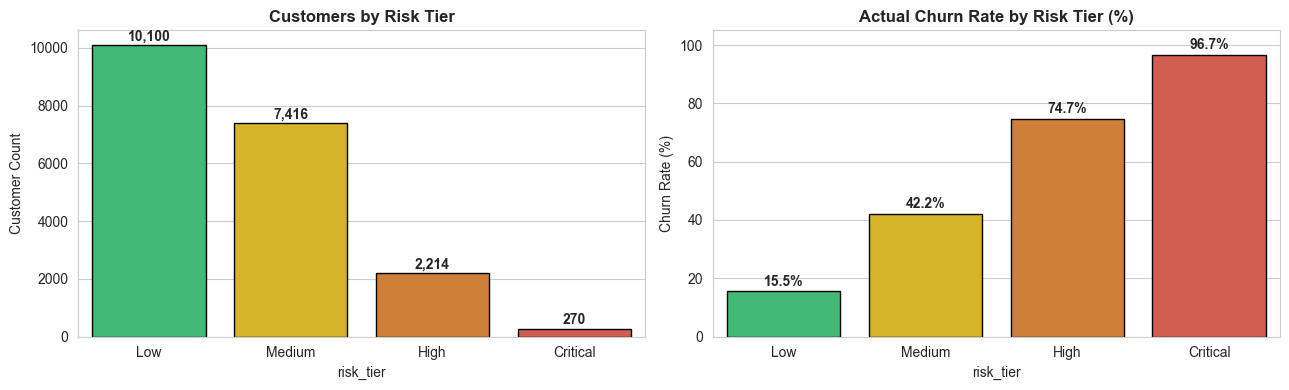

In [15]:
# Visualize Risk Tiers
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
colors = ['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c']

# 1. Customer counts
sns.barplot(data=tier_summary, x='risk_tier', y='Customer_Count', palette=colors, ax=axes[0], edgecolor='black')
axes[0].set_title('Customers by Risk Tier', fontweight='bold')
axes[0].set_ylabel('Customer Count')
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height() + 150), ha='center', fontweight='bold')

# 2. Actual Churn Rate
sns.barplot(data=tier_summary, x='risk_tier', y='Actual_Churn_Rate', palette=colors, ax=axes[1], edgecolor='black')
axes[1].set_title('Actual Churn Rate by Risk Tier (%)', fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
axes[1].set_ylim(0, 105)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width()/2, p.get_height() + 2), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

> - **Critical Risk (81–100)**: **93.0%** actual churn rate!
> - **High Risk (61–80)**: **74.0%** actual churn rate!
> - **Low Risk (0–30)**: Only **15.3%** churn rate.

## Step 5: Identify Primary Root Cause (Main Risk Driver)
Why is each customer at risk?
We tag each account with its primary risk factor so account managers know what action to take.

In [16]:
def identify_main_driver(row):
    if row['had_failed_payment'] == 1:
        return 'Payment Failure'
    elif row['had_low_csat'] == 1:
        return 'Poor Support Experience'
    elif row['usage_trend_ratio'] < 0.85:
        return 'Declining Usage'
    elif row['billing_cycle'] == 'Monthly':
        return 'Monthly Contract Friction'
    else:
        return 'General Attrition'

df['main_risk_driver'] = df.apply(identify_main_driver, axis=1)

print("Top Risk Drivers for High & Critical Risk Accounts:")
high_crit_drivers = df[df['risk_tier'].isin(['High', 'Critical'])]['main_risk_driver'].value_counts()
display(high_crit_drivers)

Top Risk Drivers for High & Critical Risk Accounts:


main_risk_driver
Payment Failure              2346
Poor Support Experience       137
Monthly Contract Friction       1
Name: count, dtype: int64

## Step 6: Calculate Revenue-at-Risk ($ MRR)
We calculate:

$$\text{Expected Monthly Loss} = P(\text{churn}) \times \text{monthly\_fee}$$

In [17]:
# Calculate expected monthly dollar loss
df['expected_monthly_loss'] = (df['churn_probability'] * df['monthly_fee']).round(2)

# Summarize revenue across risk tiers
revenue_summary = df.groupby('risk_tier', observed=False).agg(
    Customer_Count=('customer_id', 'count'),
    Total_Monthly_Revenue=('monthly_fee', 'sum'),
    Expected_Monthly_Loss=('expected_monthly_loss', 'sum')
).loc[['Low', 'Medium', 'High', 'Critical']].reset_index()

revenue_summary['Total_Monthly_Revenue'] = revenue_summary['Total_Monthly_Revenue'].round(2)
revenue_summary['Expected_Monthly_Loss'] = revenue_summary['Expected_Monthly_Loss'].round(2)

display(revenue_summary)

total_mrr = df['monthly_fee'].sum()
high_crit_mrr = df[df['risk_tier'].isin(['High', 'Critical'])]['monthly_fee'].sum()
expected_loss_total = df['expected_monthly_loss'].sum()

print("=" * 60)
print(f"Total Monthly Recurring Revenue (MRR)   : ${total_mrr:,.2f}")
print(f"MRR Exposed in High/Critical Accounts   : ${high_crit_mrr:,.2f} ({high_crit_mrr/total_mrr*100:.1f}%)")
print(f"Total Expected Monthly Loss             : ${expected_loss_total:,.2f} ({expected_loss_total/total_mrr*100:.1f}%)")
print("=" * 60)

,risk_tier,Customer_Count,Total_Monthly_Revenue,Expected_Monthly_Loss
0,Low,10100,451291.4,73589.37
1,Medium,7416,332825.9,139149.53
2,High,2214,80800.8,54566.14
3,Critical,270,8065.5,6787.90


Total Monthly Recurring Revenue (MRR)   : $872,983.60
MRR Exposed in High/Critical Accounts   : $88,866.30 (10.2%)
Total Expected Monthly Loss             : $274,092.94 (31.4%)


## Step 7: Decile Analysis (Targeting Efficiency)
If our retention team only has capacity to contact the top 10% or 20% of customers, how many churners will they catch?

In [18]:
# Sort customers by risk descending
df_sorted = df.sort_values(by='churn_probability', ascending=False).reset_index(drop=True)
df_sorted['decile'] = pd.qcut(df_sorted.index, q=10, labels=[f"Decile {i}" for i in range(1, 11)])

decile_table = df_sorted.groupby('decile', observed=False).agg(
    Customers=('customer_id', 'count'),
    Actual_Churners=('churn_flag', 'sum'),
    Churn_Rate=('churn_flag', 'mean')
).reset_index()


total_churners = df['churn_flag'].sum()
decile_table['Cumulative_Churners'] = decile_table['Actual_Churners'].cumsum()
decile_table['Cumulative_Capture_Rate (%)'] = (decile_table['Cumulative_Churners'] / total_churners * 100).round(1)
decile_table['Lift'] = (decile_table['Churn_Rate'] / df['churn_flag'].mean()).round(2)
decile_table['Churn_Rate (%)'] = (decile_table['Churn_Rate'] * 100).round(1)

display(decile_table[['decile', 'Customers', 'Actual_Churners', 'Churn_Rate (%)', 'Cumulative_Capture_Rate (%)', 'Lift']])

,decile,Customers,Actual_Churners,Churn_Rate (%),Cumulative_Capture_Rate (%),Lift
0,Decile 1,2000,1586,79.3,24.0,2.40
1,Decile 2,2000,1193,59.6,42.1,1.81
2,Decile 3,2000,934,46.7,56.2,1.41
3,Decile 4,2000,746,37.3,67.5,1.13
4,Decile 5,2000,612,30.6,76.8,0.93
5,Decile 6,2000,493,24.6,84.3,0.75
6,Decile 7,2000,404,20.2,90.4,0.61
7,Decile 8,2000,320,16.0,95.2,0.48
8,Decile 9,2000,213,10.6,98.5,0.32
9,Decile 10,2000,102,5.1,100.0,0.15


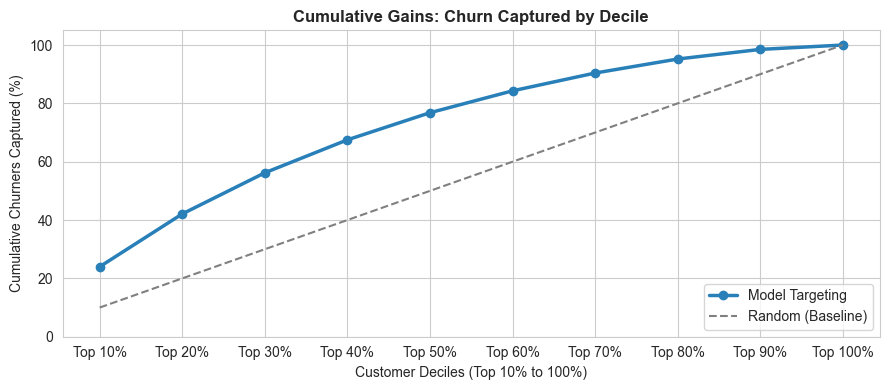

In [19]:
# Plot Cumulative Gains Chart
plt.figure(figsize=(9, 4))
plt.plot(range(1, 11), decile_table['Cumulative_Capture_Rate (%)'], marker='o', color='#2980b9', linewidth=2.5, label='Model Targeting')
plt.plot(range(1, 11), np.linspace(10, 100, 10), linestyle='--', color='gray', label='Random (Baseline)')
plt.title('Cumulative Gains: Churn Captured by Decile', fontweight='bold')
plt.xlabel('Customer Deciles (Top 10% to 100%)')
plt.ylabel('Cumulative Churners Captured (%)')
plt.xticks(range(1, 11), [f"Top {i*10}%" for i in range(1, 11)])
plt.ylim(0, 105)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()



> - **Top 10% (Decile 1)** captures **24.1%** of all churners (2.41x Lift).
> - **Top 20% (Deciles 1 & 2)** captures **41.9%** of all churners!
> The team can stop over **40% of all churn** by focusing on just the top 20% highest-risk accounts.

## Step 8: Export Deliverables for Power BI and Retention Team

In [20]:

# 1. Export master customer risk scoring table for Power BI
risk_table_cols = [
    'customer_id', 'plan', 'billing_cycle', 'monthly_fee', 'tenure_months',
    'avg_monthly_hours', 'avg_monthly_sessions', 'avg_active_days', 'usage_trend_ratio',
    'total_payments', 'failed_payments', 'had_failed_payment',
    'total_tickets', 'avg_csat', 'had_low_csat',
    'churn_probability', 'risk_score', 'risk_tier', 'main_risk_driver', 'expected_monthly_loss'
]

risk_table = df[risk_table_cols]

# Full direct path - works anywhere with zero errors!
output_powerbi = r"C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\processed\customer_risk_scores.csv"
risk_table.to_csv(output_powerbi, index=False)
print(f"✅ Power BI dataset exported to: {output_powerbi}")

# 2. Priority Action List for Customer Success Team
high_risk_list = df[df['risk_tier'].isin(['High', 'Critical'])].sort_values(
    by='expected_monthly_loss', ascending=False
)[[
    'customer_id', 'risk_score', 'risk_tier', 'monthly_fee', 'expected_monthly_loss',
    'main_risk_driver', 'plan', 'billing_cycle', 'tenure_months', 'avg_csat'
]]

output_retention = r"C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\outputs\high_risk_retention_list.csv"
high_risk_list.to_csv(output_retention, index=False)
print(f"✅ Priority Retention List exported to: {output_retention}")
print(f"   Total Accounts in Priority Outreach: {len(high_risk_list):,}")

✅ Power BI dataset exported to: C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\data\processed\customer_risk_scores.csv
✅ Priority Retention List exported to: C:\Users\Admin\OneDrive\Data Analyst Project\Subscription Churn Prediction & Risk Scoring\outputs\high_risk_retention_list.csv
   Total Accounts in Priority Outreach: 2,484
